In [16]:
#Importação das planilhas
import pandas as pd
import matplotlib.pyplot as plt

dre = pd.read_csv("dre.csv", sep=";", decimal=",", index_col="Conta", encoding="utf-8-sig")
bp = pd.read_csv("bp.csv", sep=";", decimal=",", index_col="Conta", encoding="utf-8-sig")

print(dre)
print(bp)

                               22/23    23/24    24/25    25/26
Conta                                                          
Receita operacional bruta    2252655  2641697  2941515  2569848
Receita operacional líquida  2167225  2538497  2801453  2467797
Lucro bruto                   557562   718142   722069   502057
Lucro operacional             394126   459571   532798   263536
CPV                         -1587809 -1816975 -2057444 -1873451
Resultado financeiro         -326857  -331973  -445508  -499939
LAIR                           67269   127598    87290  -236403
Lucro líquido                  78632   103496    33968  -157403
EBITDA                       1078682  1219949  1350308  1158592
                                               22/23    23/24    24/25  \
Conta                                                                    
Contas a receber                               31493    76385    51594   
Estoques                                      125907    96153   129571   


In [17]:
#Cálculo das margens
receita = dre.loc["Receita operacional líquida"]

margens = pd.DataFrame({
    "Margem bruta": dre.loc["Lucro bruto"] / receita,
    "Margem operacional": dre.loc["Lucro operacional"] / receita,
    "Margem líquida": dre.loc["Lucro líquido"] / receita,
})*100

print(margens.round(1))

       Margem bruta  Margem operacional  Margem líquida
22/23          25.7                18.2             3.6
23/24          28.3                18.1             4.1
24/25          25.8                19.0             1.2
25/26          20.3                10.7            -6.4


In [18]:
#Cálculo do crescimento da receita e da margem EBITDA
base = dre.loc[["Receita operacional líquida","EBITDA"]]
crescimento = base.pct_change(axis=1, fill_method=None)*100
margem_ebitda = dre.loc["EBITDA"] / dre.loc["Receita operacional líquida"] * 100

print(crescimento.round(1))
print(margem_ebitda.round(1))

                             22/23  23/24  24/25  25/26
Conta                                                  
Receita operacional líquida    NaN   17.1   10.4  -11.9
EBITDA                         NaN   13.1   10.7  -14.2
22/23    49.8
23/24    48.1
24/25    48.2
25/26    46.9
dtype: float64


In [19]:
#Cálculo da NCG, do ciclo operacional e do ciclo financeiro
receita = dre.loc["Receita operacional líquida"]
cpv = dre.loc["CPV"].abs()

clientes = bp.loc["Contas a receber"]
bio = bp.loc["Ativo biológico"]
estoques = bp.loc["Estoques"]
impostos = bp.loc["Impostos e contribuições a recuperar"]
fornecedores = bp.loc["Fornecedores"]
adiant = bp.loc["Adiantamento de clientes"]

ncg = clientes + bio + estoques + impostos - fornecedores - adiant

pmr = clientes / receita * 360
pme_bio = bio / cpv * 360
pme_estoq = estoques / cpv * 360
pmr_imp = impostos / cpv * 360
pmp = fornecedores / cpv * 360
pm_adiant = adiant / cpv * 360

ciclo_operacional = pmr + pme_bio + pme_estoq + pmr_imp
ciclo_financeiro = ciclo_operacional - pmp - pm_adiant

giro = pd.DataFrame({
    "NCG": ncg,
    "Ciclo operacional (dias)": ciclo_operacional,
    "Ciclo financeiro (dias)": ciclo_financeiro,
})

print(giro.round(1))
          

          NCG  Ciclo operacional (dias)  Ciclo financeiro (dias)
22/23  343090                     140.3                     75.9
23/24  237580                     120.2                     42.8
24/25  179320                     113.0                     29.0
25/26  291434                     123.7                     54.4


In [20]:
#Cálculo e montagem da planilha de endividamento
divida_bruta = (bp.loc["Emprestimos e financiamentos circulante"] + 
                bp.loc["Emprestimos e financiamentos não circulante"] +
                bp.loc["Arrendamento a pagar circulante"] +
                bp.loc["Arrendamento a pagar não circulante"]
                )
divida_liquida = divida_bruta - bp.loc["Caixa e equivalentes"]

endividamento = pd.DataFrame({
    "Dívida bruta": divida_bruta,
    "Dívida líquida": divida_liquida,
    "Dívida líquida / EBITDA (x)": divida_liquida / dre.loc["EBITDA"],
    "Dívida líquida / PL (x)": divida_liquida / bp.loc["PL"],
    "Participação de capital de terceiros (x)": divida_bruta / bp.loc["PL"],
})

print(endividamento.round(2))



       Dívida bruta  Dívida líquida  Dívida líquida / EBITDA (x)  \
22/23       3283942         2489387                         2.31   
23/24       3642809         2850302                         2.34   
24/25       3944168         3474147                         2.57   
25/26       4567540         4079137                         3.52   

       Dívida líquida / PL (x)  Participação de capital de terceiros (x)  
22/23                     4.18                                      5.51  
23/24                     3.76                                      4.80  
24/25                     4.92                                      5.59  
25/26                     6.32                                      7.08  


<Figure size 640x480 with 0 Axes>

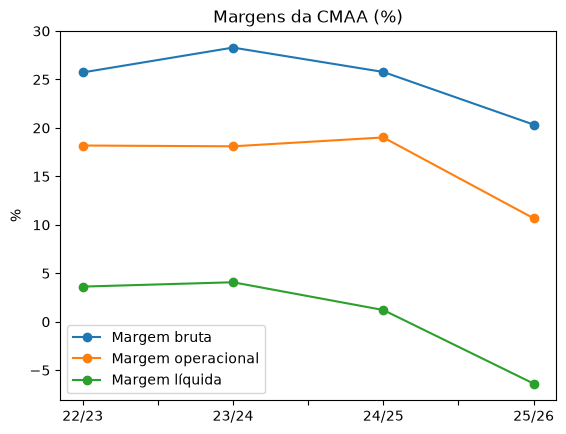

<Figure size 640x480 with 0 Axes>

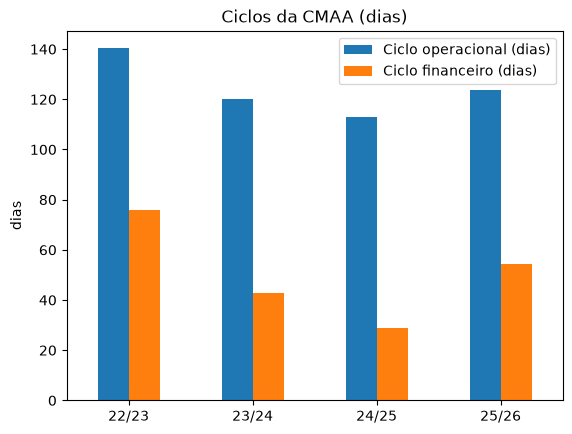

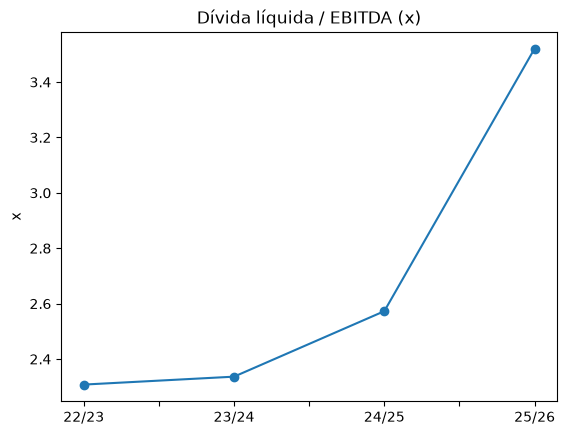

In [21]:
#Criação dos gráficos
plt.figure()
margens.plot(kind="line", marker="o", title="Margens da CMAA (%)")
plt.ylabel("%")
plt.savefig("graficos_margens.png", bbox_inches="tight")
plt.show()

plt.figure()
giro[["Ciclo operacional (dias)", 
      "Ciclo financeiro (dias)"]].plot(kind="bar",title="Ciclos da CMAA (dias)")
plt.ylabel("dias")
plt.xticks(rotation=0)
plt.savefig("graficos_ciclos.png", bbox_inches="tight")
plt.show()

plt.figure()
endividamento["Dívida líquida / EBITDA (x)"].plot(kind="line", marker="o", title="Dívida líquida / EBITDA (x)")
plt.ylabel("x")
plt.savefig("graficos_endividamento.png", bbox_inches="tight")
plt.show()

In [22]:
#Exportação em Excel
with pd.ExcelWriter("resultado_cmaa.xlsx") as arquivo:
    margens.round(1).to_excel(arquivo, sheet_name="Margens")
    crescimento.round(1).to_excel(arquivo, sheet_name="Crescimento")
    giro.round(1).to_excel(arquivo, sheet_name="Capital de giro")
    endividamento.round(2).to_excel(arquivo, sheet_name="Endividamento")